# California Housing Price Prediction
**Decision Tree Regression vs Random Forest Regression**

Notebook ini mencakup EDA, preprocessing, hyperparameter tuning, evaluasi MAE/MSE/RMSE/R², dan feature importance.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
print("Upload housing.csv dari Kaggle:")
uploaded = files.upload()
filename = next((f for f in uploaded if f.lower().endswith('.csv')), None)
if filename is None:
    raise ValueError("Upload file housing.csv (CSV) terlebih dahulu.")
df = pd.read_csv(filename)
assert 'median_house_value' in df.columns, 'Kolom target median_house_value tidak ditemukan.'
print('Ukuran dataset:', df.shape)
display(df.head())

Upload housing.csv dari Kaggle:


Saving housing.csv to housing (1).csv
Ukuran dataset: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 1. Eksplorasi data (EDA)

Tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Statistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,20640.0,NaN,NaN,NaN,-119.569704,2.003532,-124.35,-121.8,-118.49,-118.01,-114.31
latitude,20640.0,NaN,NaN,NaN,35.631861,2.135952,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,NaN,NaN,NaN,28.639486,12.585558,1.0,18.0,29.0,37.0,52.0
total_rooms,20640.0,NaN,NaN,NaN,2635.763081,2181.615252,2.0,1447.75,2127.0,3148.0,39320.0
total_bedrooms,20433.0,NaN,NaN,NaN,537.870553,421.38507,1.0,296.0,435.0,647.0,6445.0
population,20640.0,NaN,NaN,NaN,1425.476744,1132.462122,3.0,787.0,1166.0,1725.0,35682.0
households,20640.0,NaN,NaN,NaN,499.53968,382.329753,1.0,280.0,409.0,605.0,6082.0
median_income,20640.0,NaN,NaN,NaN,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,NaN,NaN,NaN,206855.816909,115395.615874,14999.0,119600.0,179700.0,264725.0,500001.0
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,jumlah_missing
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


Duplikat: 0


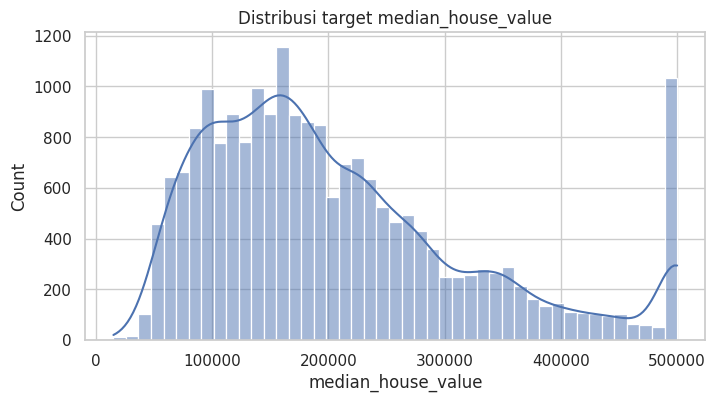

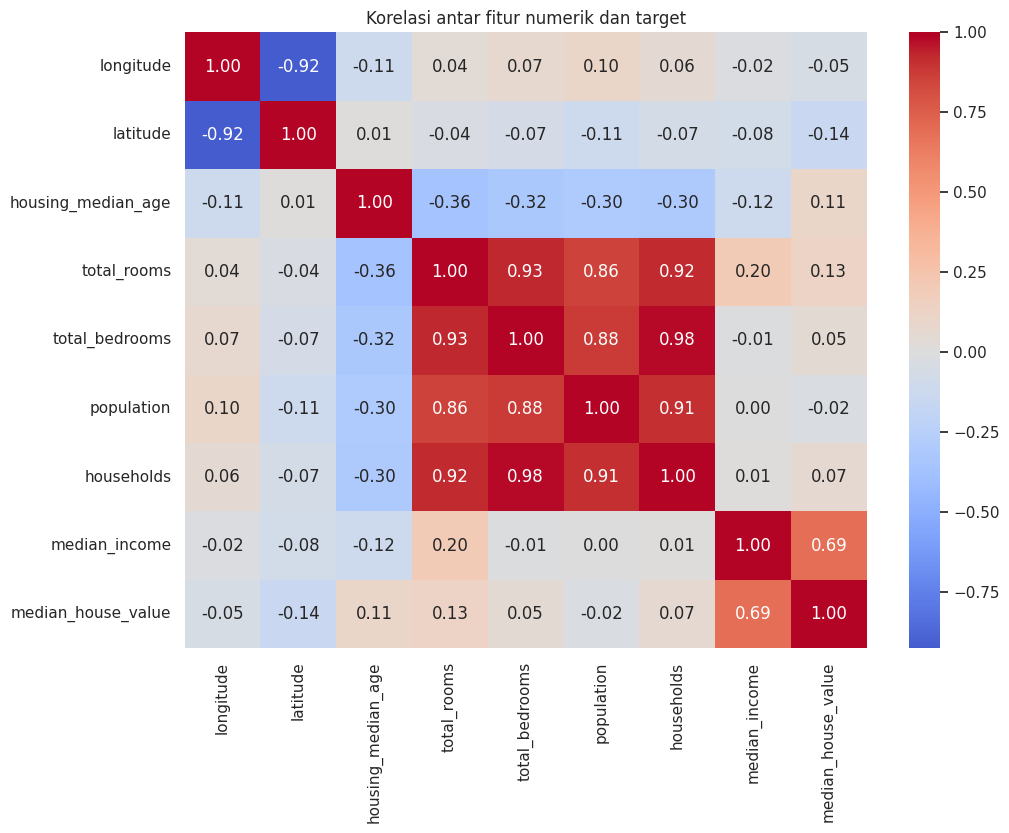

Korelasi terhadap target:


,median_house_value
median_house_value,1.000000
median_income,0.688075
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population,-0.024650
longitude,-0.045967
latitude,-0.144160


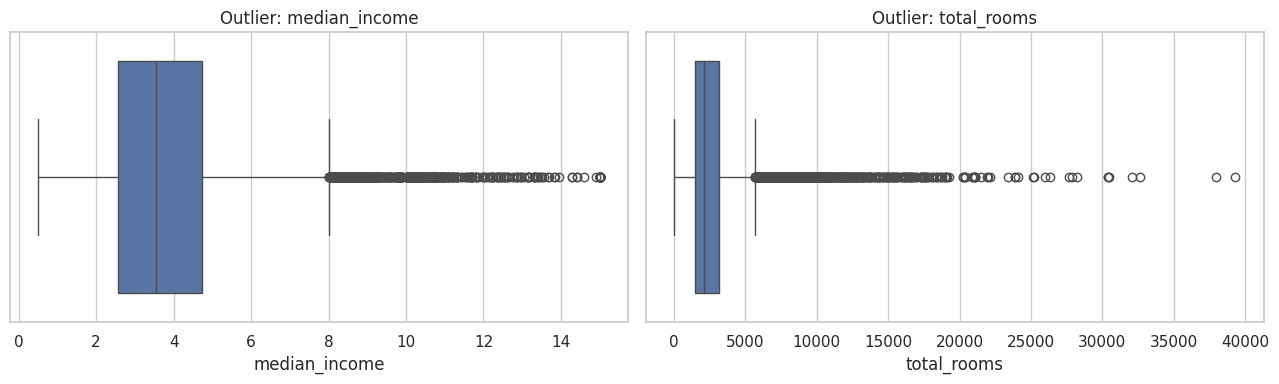

Jumlah indikasi outlier berdasarkan IQR (bukan otomatis kesalahan):


,jumlah
longitude,0
latitude,0
housing_median_age,0
total_rooms,1287
total_bedrooms,1271
population,1196
households,1220
median_income,681
median_house_value,1071


In [14]:
print('Tipe data:')
df.info()
print('\nStatistik deskriptif:')
display(df.describe(include='all').T)
print('\nMissing values:')
display(df.isna().sum().to_frame('jumlah_missing'))
print('Duplikat:', df.duplicated().sum())

fig, ax = plt.subplots(figsize=(8,4))
sns.histplot(df['median_house_value'], bins=45, kde=True, ax=ax)
ax.set_title('Distribusi target median_house_value')
plt.show()

numeric = df.select_dtypes(include=np.number)
plt.figure(figsize=(11,8))
sns.heatmap(numeric.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korelasi antar fitur numerik dan target')
plt.show()
print('Korelasi terhadap target:')
display(numeric.corr()['median_house_value'].sort_values(ascending=False))

fig, axes = plt.subplots(1,2,figsize=(13,4))
sns.boxplot(x=df['median_income'], ax=axes[0]); axes[0].set_title('Outlier: median_income')
sns.boxplot(x=df['total_rooms'], ax=axes[1]); axes[1].set_title('Outlier: total_rooms')
plt.tight_layout(); plt.show()

q1 = numeric.quantile(.25); q3 = numeric.quantile(.75); iqr = q3-q1
outlier_counts = ((numeric.lt(q1-1.5*iqr)) | (numeric.gt(q3+1.5*iqr))).sum()
print('Jumlah indikasi outlier berdasarkan IQR (bukan otomatis kesalahan):')
display(outlier_counts.to_frame('jumlah'))

## 2. Split dan preprocessing
Imputasi dan encoding dipasang dalam pipeline sehingga hanya dipelajari dari data training pada tiap fold. Outlier tidak otomatis dibuang. Model pohon tidak memerlukan scaling.

In [15]:
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
preprocess = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), num_cols),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])
print('Training:', X_train.shape, '| Testing:', X_test.shape)
print('Numerik:', num_cols)
print('Kategorikal:', cat_cols)

Training: (16512, 9) | Testing: (4128, 9)
Numerik: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Kategorikal: ['ocean_proximity']


## 3. Modeling dan hyperparameter tuning
Pencarian parameter dilakukan pada training set dengan 3-fold cross-validation. Sel Random Forest dapat memerlukan beberapa menit.

In [16]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)
dt = Pipeline([('prep',preprocess),('model',DecisionTreeRegressor(random_state=42))])
rf = Pipeline([('prep',preprocess),('model',RandomForestRegressor(random_state=42, n_jobs=1))])
dt_params = {
 'model__max_depth':[5,10,15,20,None],
 'model__min_samples_split':[2,5,10,20],
 'model__min_samples_leaf':[1,2,4,8]
}
rf_params = {
 'model__n_estimators':[100,200,300],
 'model__max_depth':[10,20,30,None],
 'model__min_samples_split':[2,5,10],
 'model__min_samples_leaf':[1,2,4],
 'model__max_features':[0.7,1.0]
}
dt_search = RandomizedSearchCV(dt, dt_params, n_iter=15, scoring='neg_root_mean_squared_error', cv=cv, random_state=42, n_jobs=-1)
rf_search = RandomizedSearchCV(rf, rf_params, n_iter=12, scoring='neg_root_mean_squared_error', cv=cv, random_state=42, n_jobs=-1)
dt_search.fit(X_train,y_train)
print('Decision Tree best params:',dt_search.best_params_)
print('Decision Tree CV RMSE:',-dt_search.best_score_)
rf_search.fit(X_train,y_train)
print('Random Forest best params:',rf_search.best_params_)
print('Random Forest CV RMSE:',-rf_search.best_score_)

Decision Tree best params: {'model__min_samples_split': 20, 'model__min_samples_leaf': 8, 'model__max_depth': 10}
Decision Tree CV RMSE: 61261.23805703996
Random Forest best params: {'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 30}
Random Forest CV RMSE: 49751.75978670028


## 4. Evaluasi pada testing set

,MAE,MSE,RMSE,R2
Model,,,,
Decision Tree,39744.3071,3.599901e+09,59999.1762,0.7253
Random Forest,31649.4095,2.381441e+09,48800.0110,0.8183


Model dengan RMSE testing terendah: Random Forest


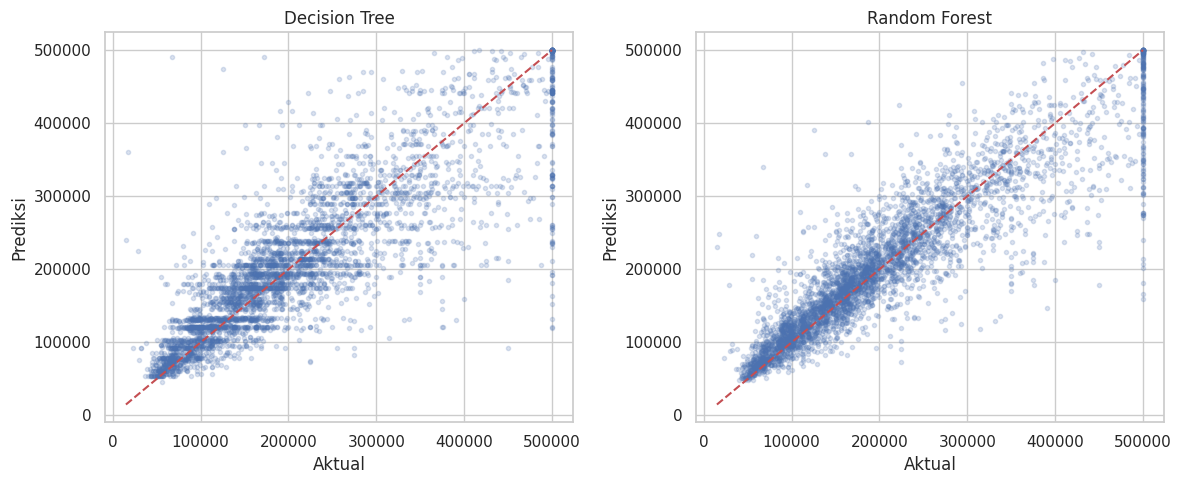

In [17]:
models = {'Decision Tree':dt_search.best_estimator_, 'Random Forest':rf_search.best_estimator_}
rows=[]
for name, model in models.items():
    pred=model.predict(X_test)
    mse=mean_squared_error(y_test,pred)
    rows.append({'Model':name,'MAE':mean_absolute_error(y_test,pred),
                 'MSE':mse,'RMSE':np.sqrt(mse),'R2':r2_score(y_test,pred)})
results=pd.DataFrame(rows).set_index('Model')
display(results.round(4))
print('Model dengan RMSE testing terendah:',results['RMSE'].idxmin())

fig, axes=plt.subplots(1,2,figsize=(12,5))
for ax,(name,model) in zip(axes,models.items()):
    pred=model.predict(X_test)
    ax.scatter(y_test,pred,alpha=.2,s=9)
    lim=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())]
    ax.plot(lim,lim,'r--'); ax.set_title(name)
    ax.set_xlabel('Aktual'); ax.set_ylabel('Prediksi')
plt.tight_layout(); plt.show()

## 5. Feature importance
Permutation importance dihitung pada testing set menggunakan RMSE; angka positif lebih besar berarti fitur lebih berpengaruh pada performa prediksi. Ini bukan bukti kausalitas.

Model: Random Forest


,fitur,importance_RMSE,std
7,median_income,54434.877924,765.206098
0,longitude,44126.002715,463.291939
1,latitude,34770.809792,419.980328
8,ocean_proximity,23401.109074,319.499517
2,housing_median_age,5339.113373,29.246332
5,population,5239.490715,216.778198
3,total_rooms,2794.036535,114.189272
4,total_bedrooms,1932.471867,150.611444
6,households,831.028578,88.954117


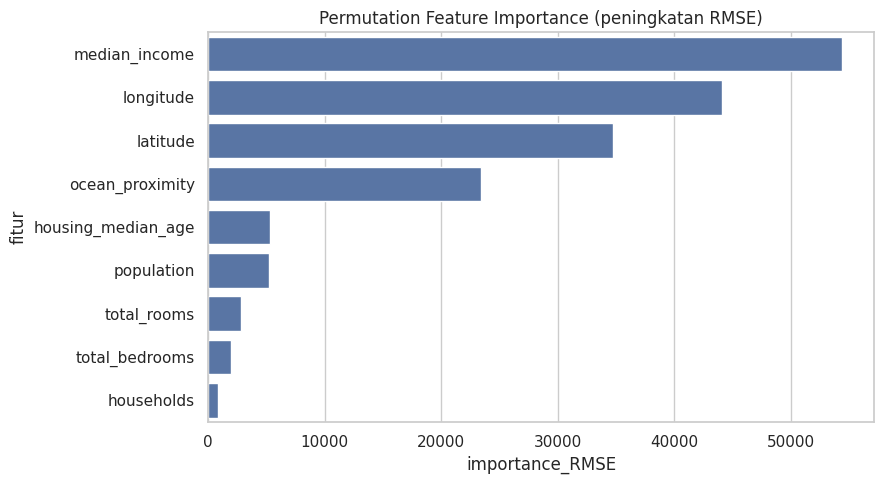

In [18]:
best_name=results['RMSE'].idxmin()
best_model=models[best_name]
pi=permutation_importance(best_model,X_test,y_test,n_repeats=3,random_state=42,
                          scoring='neg_root_mean_squared_error',n_jobs=-1)
importance=pd.DataFrame({'fitur':X_test.columns,'importance_RMSE':pi.importances_mean,
                         'std':pi.importances_std}).sort_values('importance_RMSE',ascending=False)
print('Model:',best_name)
display(importance)
plt.figure(figsize=(9,5))
sns.barplot(data=importance,x='importance_RMSE',y='fitur')
plt.title('Permutation Feature Importance (peningkatan RMSE)')
plt.tight_layout();plt.show()

## 6. Analisis


In [19]:

print('Ukuran dataset:', df.shape)
print('Missing values:', df.isna().sum()[df.isna().sum() > 0].to_dict())
print('Parameter terbaik DT:', dt_search.best_params_)
print('Parameter terbaik RF:', rf_search.best_params_)

print('\nEvaluasi testing:')
print(results.round(3).to_string())

print('\n3 fitur teratas:')
print(importance.head(3).to_string(index=False))

print('\nRekomendasi berdasarkan RMSE testing:', best_name)

# Menyimpan hasil eksperimen
results.to_csv('hasil_evaluasi.csv')
importance.to_csv('feature_importance.csv', index=False)


Ukuran dataset: (20640, 10)
Missing values: {'total_bedrooms': 207}
Parameter terbaik DT: {'model__min_samples_split': 20, 'model__min_samples_leaf': 8, 'model__max_depth': 10}
Parameter terbaik RF: {'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 30}

Evaluasi testing:
                     MAE           MSE       RMSE     R2
Model                                                   
Decision Tree  39744.307  3.599901e+09  59999.176  0.725
Random Forest  31649.410  2.381441e+09  48800.011  0.818

3 fitur teratas:
        fitur  importance_RMSE        std
median_income     54434.877924 765.206098
    longitude     44126.002715 463.291939
     latitude     34770.809792 419.980328

Rekomendasi berdasarkan RMSE testing: Random Forest


In [20]:

# Membandingkan performa training dan testing
for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_pred)
    )
    test_rmse = np.sqrt(
        mean_squared_error(y_test, test_pred)
    )

    print(f"\n{name}")
    print(f"Training RMSE: {train_rmse:.3f}")
    print(f"Testing RMSE : {test_rmse:.3f}")
    print(f"Gap RMSE     : {test_rmse - train_rmse:.3f}")



Decision Tree
Training RMSE: 51152.498
Testing RMSE : 59999.176
Gap RMSE     : 8846.679

Random Forest
Training RMSE: 22181.147
Testing RMSE : 48800.011
Gap RMSE     : 26618.864
